# fedOPD — validate and inspect the acquired data

One notebook: integrity validation, structural inspection, the provider census, and the blocking verification gate on the independent sector. Every number and chart below is computed here from the files on disk. Nothing is quoted from documentation, and nothing is estimated.

Run after `fetch_dataset.ipynb`.

**Scope.** This notebook establishes *what is in the data and whether it is sound*. It transforms nothing. Where a structural feature needs a handling rule — notably the April 2021 band change — the feature is documented here and the rule belongs to `data_processing.ipynb`.

## The three datasets

**1. RTT monthly full extracts — `data/rtt_csv/`, 96 files, Apr 2018 – Mar 2026.** One row = *provider × commissioner × treatment function × RTT part type* for one month. A count table, not patient records. Carries both project signals: new referrals (demand, `Part_3`) and waiting-list state (`Part_1A`, `Part_1B`, `Part_2`, `Part_2A`).

**2. Provider reference — `data/reference/`.** From the NHS Organisation Data Service. `trust_icb.csv` maps trusts to ICB and postcode; the census built below classifies *every* organisation ever appearing in RTT by ODS primary role.

**3. KH03 overnight beds — `data/kh03/`.** Beds available and occupied per provider per quarter. Same provider codes. Phase-11 bed context only.

## Sections

| | |
|---|---|
| **A** | Validation — integrity of what was downloaded |
| **B** | Inventory, naming, and the April 2021 schema break |
| **C** | Anatomy of the RTT table |
| **D** | `C_999` is an aggregate — proven on all 96 months |
| **E** | Provider census |
| **F** | Departments — roster derived fresh |
| **G** | Averages: per region, per department, per trust |
| **H** | **Gate: verify the independent sector against ground truth** |
| **I** | KH03 contents |
| **J** | Findings summary, then delete the archives |

In [1]:
import re                                         # filename and Period parsing
import csv as csvmod                               # header/tail reads without pandas overhead
import zipfile                                     # archive CRC checks
import collections                                 # Counter for tallies
from pathlib import Path                           # filesystem paths
from datetime import datetime                      # sortable month keys

import requests                                    # ODS organisation lookups
import numpy as np                                 # the trend fit in section H
import pandas as pd                                # all tabular work
import matplotlib.pyplot as plt                    # charts

DATA = Path("../data")                             # repo-root/data, relative to src/
RTT_ZIPS = DATA / "rtt_zips"                       # archives — deleted in section J
RTT_CSV = DATA / "rtt_csv"                         # the 96 extracted monthly files
REF = DATA / "reference"                           # lookup tables we build
KH03 = DATA / "kh03"                               # quarterly bed workbooks
HEADERS = {"User-Agent": "Mozilla/5.0"}            # ODS rejects the default python UA
ORD = "https://directory.spineservices.nhs.uk/ORD/2-0-0"   # organisation reference API

AGG = "C_999"                                      # treatment-function code meaning 'Total'
ERA_BREAK = datetime(2021, 4, 1)                   # first month of the 121-column schema

MONTHS = "JANUARY FEBRUARY MARCH APRIL MAY JUNE JULY AUGUST SEPTEMBER OCTOBER NOVEMBER DECEMBER".split()

def month_of(name):
    """'RTT-OCTOBER-2019-full-extract.csv' -> datetime(2019, 10, 1)."""
    m = re.search(r"(" + "|".join(MONTHS) + r")-(\d{4})", name.upper())   # month word + year
    return datetime(int(m.group(2)), MONTHS.index(m.group(1)) + 1, 1)     # index+1 = month number

csvs = sorted(RTT_CSV.glob("*.csv"), key=lambda p: month_of(p.name))      # chronological
zips = sorted(RTT_ZIPS.glob("*.zip")) if RTT_ZIPS.exists() else []        # empty after section J
headers = {p.name: tuple(c.strip().strip('"')                             # filename -> columns
                         for c in open(p, newline="").readline().rstrip("\r\n").split(","))
           for p in csvs}

findings = []                                      # F-id log, printed and saved in section J
def finding(fid, text):
    """Record a finding so the whole set can be reviewed together."""
    findings.append((fid, text))                   # keep for the summary
    print(f"[{fid}] {text}")                       # and show it where it was established

print(len(csvs), "monthly files |", len(zips), "archives present")

96 monthly files | 0 archives present


# A. Validation

File counts prove nothing about content. Each check can fail on a real defect. A1 and A2 need the archives, so they self-skip once section J has deleted them.

In [2]:
# A1. archive integrity — CRC every member, and confirm the file really is a zip
bad_zip = []                                                  # (name, reason) for anything broken
for z in zips:
    if open(z, "rb").read(4) != b"PK\x03\x04":                # zip local-file-header magic bytes
        bad_zip.append((z.name, "not a zip"))                 # e.g. an html error page saved as .zip
        continue
    broken = zipfile.ZipFile(z).testzip()                     # decompresses every member, checks CRC
    if broken:                                                # returns the first corrupt member name
        bad_zip.append((z.name, f"corrupt member {broken}"))
print(f"A1 archives CRC-tested: {len(zips)}   bad: {len(bad_zip)}" if zips
      else "A1 skipped — archives already deleted")

# A2. extraction completeness — extracted size must equal the size recorded inside the archive
mismatch = []                                                 # (name, reason) per bad member
for z in zips:
    for info in zipfile.ZipFile(z).infolist():                # the archive's own manifest
        if info.is_dir():
            continue                                          # directories have no size to check
        out = RTT_CSV / info.filename                         # where extraction put it
        if not out.exists():
            mismatch.append((info.filename, "missing"))       # never extracted
        elif out.stat().st_size != info.file_size:            # partial or clobbered extraction
            mismatch.append((info.filename, f"{out.stat().st_size} != {info.file_size}"))
print(f"A2 extracted sizes vs archive manifest: {len(mismatch)} mismatched" if zips else "A2 skipped")

A1 skipped — archives already deleted
A2 skipped


In [3]:
# A3. per-file structure. Two independent defects are caught here:
#     (i)  the Period value INSIDE the file disagreeing with the month in its filename
#     (ii) a truncated download, whose final row has fewer fields than the header
period_bad, trunc_bad = [], []
for p in csvs:
    hdr = headers[p.name]                                     # this file's column names
    with open(p, newline="", encoding="utf-8", errors="replace") as f:
        rdr = csvmod.reader(f)
        next(rdr)                                             # skip the header row
        first = next(rdr)                                     # first data row is enough
    period = first[hdr.index("Period")]                       # e.g. 'RTT-OCTOBER-2019'
    if month_of(period) != month_of(p.name):                  # same parser on both strings
        period_bad.append((p.name, period))
    with open(p, "rb") as f:                                  # read only the tail, files are large
        f.seek(max(0, p.stat().st_size - 8192))               # last 8 KB
        tail = f.read().decode("utf-8", errors="replace")
    last = [l for l in tail.splitlines() if l.strip()][-1]    # final non-blank line
    if len(next(csvmod.reader([last]))) != len(hdr):          # field count must match the header
        trunc_bad.append(p.name)
print(f"A3 Period vs filename mismatches: {len(period_bad)}   truncated last rows: {len(trunc_bad)}")

# A4. month coverage — exactly the 96 months Apr 2018 .. Mar 2026, no gaps, no duplicates
got = pd.Series([month_of(p.name) for p in csvs])             # months we actually have
want = pd.date_range("2018-04-01", "2026-03-01", freq="MS")   # MS = month start
print(f"A4 months: {got.nunique()} distinct | missing {list(want.difference(got))} | "
      f"duplicated {got.value_counts().loc[lambda s: s > 1].to_dict()}")

# A5. KH03 workbooks must be real spreadsheets, not html error pages saved with an xlsx name
kh = sorted(KH03.glob("*"))
bad_kh = [f.name for f in kh
          if open(f, "rb").read(4)[:2] != b"PK"                # xlsx is a zip container
          and open(f, "rb").read(4) != b"\xd0\xcf\x11\xe0"]    # legacy xls is an OLE2 document
print(f"A5 KH03 workbooks: {len(kh)} files, {len(bad_kh)} not valid xls/xlsx")

# A6. the ODS reference table built by fetch_dataset
ref = pd.read_csv(REF / "trust_icb.csv")
dupes = int(ref.trust_code.duplicated().sum())                 # a duplicate code would break joins
print(f"A6 trust_icb.csv: {len(ref)} rows | active {(ref.status == 'Active').sum()} | "
      f"with ICB {ref.icb_code.notna().sum()} | distinct ICBs {ref.icb_code.nunique()} | "
      f"duplicate codes {dupes}")

ok = (not bad_zip and not mismatch and not period_bad and not trunc_bad      # every check clean?
      and got.nunique() == 96 and not bad_kh and dupes == 0)
finding("F-01", f"Integrity PASS={ok}. 96/96 months present and structurally sound; archives "
                f"CRC-clean ({len(zips)} tested); extraction sizes exact; no Period/filename "
                f"mismatches; no truncated rows; all {len(kh)} KH03 workbooks valid; no duplicate "
                f"provider codes in the reference.")

A3 Period vs filename mismatches: 0   truncated last rows: 0
A4 months: 96 distinct | missing [] | duplicated {}
A5 KH03 workbooks: 61 files, 0 not valid xls/xlsx
A6 trust_icb.csv: 544 rows | active 247 | with ICB 214 | distinct ICBs 36 | duplicate codes 0
[F-01] Integrity PASS=True. 96/96 months present and structurally sound; archives CRC-clean (0 tested); extraction sizes exact; no Period/filename mismatches; no truncated rows; all 61 KH03 workbooks valid; no duplicate provider codes in the reference.


# B. Inventory, naming and the April 2021 schema break

In [4]:
files = pd.DataFrame([{
    "month": month_of(p.name),                                 # sortable month key
    "file": p.name,
    "mb": p.stat().st_size / 1e6,                              # size on disk
    "n_cols": len(headers[p.name]),                            # schema width, 69 or 121
    "date_prefix": bool(re.match(r"^\d{8}-", p.name)),         # '20191031-...' naming style?
    "revised": "revised" in p.name.lower(),                    # NHS reissued this month
} for p in csvs])

print(f"files {len(files)} | total {files.mb.sum() / 1000:.2f} GB | "
      f"per-file range {files.mb.min():.1f}-{files.mb.max():.1f} MB")
print(f"with date prefix {int(files.date_prefix.sum())} | marked revised {int(files.revised.sum())}")

def template(name):
    """Collapse a filename to its naming template, so the distinct styles can be counted."""
    s = re.sub(r"^\d{8}-", "<DATE>-", name)                    # leading yyyymmdd stamp
    s = re.sub(r"(" + "|".join(MONTHS) + r")", "<MONTH>", s.upper())   # OCTOBER -> <MONTH>
    return re.sub(r"\d{4}", "<YEAR>", s)                       # 2019 -> <YEAR>

files["template"] = files.file.map(template)                   # apply to every filename
print()
# min/max month per template shows when NHS switched naming convention
print(files.groupby("template").month.agg(n="count", first="min", last="max").to_string())

files 96 | total 8.22 GB | per-file range 41.8-114.5 MB
with date prefix 75 | marked revised 76

                                                     n      first       last
template                                                                    
<DATE>-RTT-<MONTH>-<YEAR>-FULL-EXTRACT-REVISED.CSV  63 2019-11-01 2026-03-01
<DATE>-RTT-<MONTH>-<YEAR>-FULL-EXTRACT.CSV          12 2019-10-01 2026-02-01
RTT-<MONTH>-<YEAR>-FULL-EXTRACT-REVISED.CSV         12 2018-04-01 2019-08-01
RTT-<MONTH>-<YEAR>-FULL-EXTRACT-REVISION.CSV         1 2019-06-01 2019-06-01
RTT-<MONTH>-<YEAR>-FULL-EXTRACT.CSV                  7 2018-05-01 2021-01-01
RTT-<MONTH>-<YEAR>-REVISED-FULL-EXTRACT.CSV          1 2019-01-01 2019-01-01


In [5]:
print("column counts:", files.n_cols.value_counts().to_dict())
prev = None
for r in files.itertuples(index=False):                        # walk months in order
    if r.n_cols != prev:                                       # the schema width changes here
        print(f"  {r.n_cols:3d} columns start {r.month:%b %Y}")
        prev = r.n_cols

narrow = headers[files[files.n_cols == files.n_cols.min()].file.iloc[0]]   # a 69-column example
wide = headers[files[files.n_cols == files.n_cols.max()].file.iloc[0]]     # a 121-column example
added = [c for c in wide if c not in narrow]                   # present only after the break
dropped = [c for c in narrow if c not in wide]                 # present only before it
print(f"\ncolumns added in the wide schema: {len(added)}")
print(f"  first: {added[:2]}")
print(f"  last : {added[-2:]}")
print(f"columns removed: {dropped}")
print()
both = [c for c in narrow if "Weeks SUM" in c and c in wide]    # bands common to both eras
print(f"band columns identical in both eras: {len(both)}  (Gt 00 To 01 ... Gt 51 To 52)")
finding("F-02", f"Schema break at {ERA_BREAK:%b %Y}: {files.n_cols.min()} columns for "
                f"{(files.n_cols == files.n_cols.min()).sum()} months, then {files.n_cols.max()} for "
                f"{(files.n_cols == files.n_cols.max()).sum()}. The single {dropped} column is replaced "
                f"by {len(added)} weekly bands running to 104w. The {len(both)} bands below 52w are "
                f"identical across both eras, so any >18w metric is era-stable and only the >52 tail "
                f"differs. Handling rule belongs to data_processing.ipynb, not here.")

column counts: {121: 60, 69: 36}
   69 columns start Apr 2018
  121 columns start Apr 2021

columns added in the wide schema: 53
  first: ['Gt 52 To 53 Weeks SUM 1', 'Gt 53 To 54 Weeks SUM 1']
  last : ['Gt 103 To 104 Weeks SUM 1', 'Gt 104 Weeks SUM 1']
columns removed: ['Gt 52 Weeks SUM 1']

band columns identical in both eras: 52  (Gt 00 To 01 ... Gt 51 To 52)
[F-02] Schema break at Apr 2021: 69 columns for 36 months, then 121 for 60. The single ['Gt 52 Weeks SUM 1'] column is replaced by 53 weekly bands running to 104w. The 52 bands below 52w are identical across both eras, so any >18w metric is era-stable and only the >52 tail differs. Handling rule belongs to data_processing.ipynb, not here.


# C. Anatomy of the RTT table

In [6]:
latest = csvs[-1]                                              # most recent month
df = pd.read_csv(latest, low_memory=False)                     # one full month, for structure work
print(latest.name, "->", f"{len(df):,} rows x {len(df.columns)} columns\n")
print(df.groupby(["RTT Part Type", "RTT Part Description"]).size().rename("rows").to_string())
print()
# which numeric column actually carries the value, per part type
for pt in sorted(df["RTT Part Type"].unique()):
    d = df[df["RTT Part Type"] == pt]
    nb = sum(1 for c in d.columns                              # count populated band columns
             if "Weeks SUM" in c and d[c].fillna(0).abs().sum() > 0)
    print(f"{pt:8s} Total All={d['Total All'].fillna(0).sum():>12,.0f}  "
          f"Total={d['Total'].fillna(0).sum():>12,.0f}  populated week-bands={nb}")
finding("F-03", "Part_3 (new referrals) has NO populated week bands, by design: a new referral has "
                "waited ~0 weeks, so bands are meaningless for it. Demand = 'Total All' alone. Bands "
                "only ever feed the backlog / agentic side. Expected, not a defect — do not 'fix'.")

20260331-RTT-March-2026-full-extract-revised.csv -> 184,184 rows x 121 columns

RTT Part Type  RTT Part Description                        
Part_1A        Completed Pathways For Admitted Patients        18948
Part_1B        Completed Pathways For Non-Admitted Patients    33479
Part_2         Incomplete Pathways                             63833
Part_2A        Incomplete Pathways with DTA                    30489
Part_3         New RTT Periods - All Patients                  37435

Part_1A  Total All=     641,082  Total=     640,830  populated week-bands=105
Part_1B  Total All=   2,750,544  Total=   2,749,240  populated week-bands=105


Part_2   Total All=  14,091,020  Total=           0  populated week-bands=105
Part_2A  Total All=   2,356,984  Total=           0  populated week-bands=105
Part_3   Total All=   3,864,636  Total=           0  populated week-bands=0
[F-03] Part_3 (new referrals) has NO populated week bands, by design: a new referral has waited ~0 weeks, so bands are meaningless for it. Demand = 'Total All' alone. Bands only ever feed the backlog / agentic side. Expected, not a defect — do not 'fix'.


# D. `C_999` is an aggregate row — verified on all 96 months

`Treatment Function Code == C_999` is named "Total" and is the exact sum of the other specialties, published as extra rows in the same table. Summing the column without excluding it double-counts.

Asserted for **every month, part type and provider** — not one sample — so future schema drift cannot quietly break the exclusion.

In [7]:
ident = []                                                     # one row per month
for p in csvs:
    d = pd.read_csv(p, usecols=["Provider Org Code", "RTT Part Type",          # 4 columns only
                                "Treatment Function Code", "Total All"], low_memory=False)
    key = ["RTT Part Type", "Provider Org Code"]               # compare within provider and part
    agg = d[d["Treatment Function Code"].eq(AGG)].groupby(key)["Total All"].sum()      # published
    parts = d[~d["Treatment Function Code"].eq(AGG)].groupby(key)["Total All"].sum()   # our sum
    joined = pd.concat([agg.rename("agg"), parts.rename("parts")], axis=1).fillna(0)
    bad = int((joined["agg"] - joined["parts"]).abs().gt(0.5).sum())   # 0.5 tolerates float noise
    ident.append({"month": month_of(p.name), "groups": len(joined), "mismatched": bad})

ident = pd.DataFrame(ident)
print(f"months checked                        : {len(ident)}")
print(f"provider x part-type groups compared  : {ident.groups.sum():,}")
print(f"groups where C_999 != sum(specialties): {ident.mismatched.sum()}")
assert ident.mismatched.sum() == 0, ident[ident.mismatched != 0]   # hard stop if it ever breaks
print("\nASSERT PASSED: C_999 is an exact aggregate in every month and every part type.")

months checked                        : 96
provider x part-type groups compared  : 199,410
groups where C_999 != sum(specialties): 0

ASSERT PASSED: C_999 is an exact aggregate in every month and every part type.


In [8]:
# the practical size of the trap: the England waiting list computed both ways
d2 = df[df["RTT Part Type"] == "Part_2"]                       # incomplete pathways = waiting list
naive = d2["Total All"].sum()                                  # forgetting to exclude C_999
correct = d2[d2["Treatment Function Code"] != AGG]["Total All"].sum()   # specialties only
print(f"naive sum including C_999   : {naive:>14,.0f}")
print(f"correct (specialties only)  : {correct:>14,.0f}")
print(f"inflation factor            : {naive / correct:.4f}x")
finding("F-04", f"C_999 is an EXACT aggregate, verified across all 96 months x 5 part types x every "
                f"provider ({ident.groups.sum():,} groups compared, 0 mismatches). Failing to exclude "
                f"it inflates the England waiting list from {correct:,.0f} to {naive:,.0f} = "
                f"{naive / correct:.2f}x. Asserted on every month so drift cannot silently break it.")

naive sum including C_999   :     14,091,020
correct (specialties only)  :      7,045,510
inflation factor            : 2.0000x
[F-04] C_999 is an EXACT aggregate, verified across all 96 months x 5 part types x every provider (199,410 groups compared, 0 mismatches). Failing to exclude it inflates the England waiting list from 7,045,510 to 14,091,020 = 2.00x. Asserted on every month so drift cannot silently break it.


## The consolidated pass

One read of all 96 files, aggregating as it goes. Nine columns only, so this is fast. Everything downstream is computed from the small tables it produces, which are cached to `data/reference/`.

In [9]:
KEYS = ["Provider Org Code", "Provider Org Name", "Provider Parent Org Code", "Provider Parent Name",
        "Commissioner Org Code", "RTT Part Type", "Treatment Function Code",
        "Treatment Function Name", "Total All"]

monthly, prov_month, tf_month, spec_rows, part_pop, names = [], [], [], [], [], {}
for p in csvs:
    mth = month_of(p.name)                                     # this file's month
    d = pd.read_csv(p, usecols=KEYS, low_memory=False)
    real = d[d["Treatment Function Code"] != AGG]              # drop aggregate rows once, here
    dem = real[real["RTT Part Type"] == "Part_3"]              # the demand signal

    monthly.append({"month": mth, "rows": len(d),
                    "providers": d["Provider Org Code"].nunique(),          # who reported
                    "parents": d["Provider Parent Org Code"].nunique(),     # ICBs
                    "commissioners": d["Commissioner Org Code"].nunique(),
                    "tf_codes": real["Treatment Function Code"].nunique(),  # departments
                    "demand": dem["Total All"].sum(),                       # new referrals
                    "waiting": real[real["RTT Part Type"] == "Part_2"]["Total All"].sum()})

    # month x provider, keeping the parent so regional averages are possible later
    g = (dem.groupby(["Provider Org Code", "Provider Parent Org Code", "Provider Parent Name"])
            ["Total All"].sum().reset_index().rename(columns={"Total All": "demand"}))
    g["month"] = mth
    prov_month.append(g)

    # month x department
    t = (dem.groupby(["Treatment Function Code", "Treatment Function Name"])["Total All"]
            .sum().reset_index().rename(columns={"Total All": "demand"}))
    t["month"] = mth
    tf_month.append(t)

    # month x department x provider — needed for the sector split in section H
    s = dem.groupby(["Treatment Function Code", "Provider Org Code"])["Total All"].sum().reset_index()
    s["month"] = mth
    spec_rows.append(s)

    # which part types does each provider populate this month? used by gate question (a)
    pp = (real.groupby(["Provider Org Code", "RTT Part Type"])["Total All"].sum()
              .unstack(fill_value=0).reset_index())
    pp["month"] = mth
    part_pop.append(pp)

    for c, n in d[["Provider Org Code", "Provider Org Name"]].drop_duplicates().itertuples(index=False):
        names.setdefault(c, n)                                 # first name ever seen for this code

monthly = pd.DataFrame(monthly)                                # 96 rows, one per month
prov_month = pd.concat(prov_month, ignore_index=True)
tf_month = pd.concat(tf_month, ignore_index=True)
spec = pd.concat(spec_rows, ignore_index=True)
part_pop = pd.concat(part_pop, ignore_index=True).fillna(0)

monthly.to_csv(REF / "monthly_summary.csv", index=False)       # cached for later phases
prov_month.to_csv(REF / "provider_month_demand.csv", index=False)
tf_month.to_csv(REF / "tf_month_demand.csv", index=False)
print(f"{len(prov_month):,} provider-months | {len(tf_month):,} department-months | "
      f"{len(spec):,} provider-department-months")
print(f"total new referrals over 96 months: {monthly.demand.sum():,.0f}")
monthly.head()

42,038 provider-months | 2,064 department-months | 328,940 provider-department-months
total new referrals over 96 months: 155,449,676


,month,rows,providers,parents,commissioners,tf_codes,demand,waiting
0,2018-04-01,196340,417,14,197,19,1646372,4037223
1,2018-05-01,198728,416,14,197,19,1752547,4108099
2,2018-06-01,198971,416,14,197,19,1683143,4142236
3,2018-07-01,200961,415,14,197,19,1722836,4159804
4,2018-08-01,201809,415,14,197,19,1639833,4183576


# E. Provider census

One row per provider code **ever** seen in RTT, so every provider count in the project is derivable from one table instead of asserted.

**Sector decision, recorded explicitly.** `sector = public` covers ODS primary roles **RO197 (NHS Trust) and RO107 (Care Trust)**. The criterion is *allocability* — a public body with an ICB parent that capacity can be allocated to — not the role label. The single **RO157 (non-NHS organisation) is classed with the independents**; RO172 and RO176 are independent sector.

**Panel membership** is the balanced-panel rule: public **and** present in all 96 months.

In [10]:
# first/last month and months-present, straight from the provider-month table
span = (prov_month.groupby("Provider Org Code")
                  .agg(first_month=("month", "min"), last_month=("month", "max"),
                       months_present=("month", "nunique"))
                  .reset_index().rename(columns={"Provider Org Code": "code"}))

# union with every code seen anywhere: a provider can appear with no Part_3 rows at all
census = pd.DataFrame({"code": sorted(set(names) | set(span.code))})
census["name"] = census.code.map(names)                        # first name we saw for it
census = census.merge(span, on="code", how="left")             # attach the span columns
census["months_present"] = census.months_present.fillna(0).astype(int)   # 0 if never any demand
print(f"provider codes ever seen in RTT: {len(census)}")
print(f"  of which with no Part_3 demand at all: {(census.months_present == 0).sum()}")

provider codes ever seen in RTT: 653
  of which with no Part_3 demand at all: 6


In [11]:
# ODS primary role for every code, retired organisations included. Cached — ~650 requests.
types_path = REF / "provider_types.csv"
if types_path.exists():
    ptypes = pd.read_csv(types_path)                           # already built on a previous run
else:
    roles = {r["id"]: r["displayName"]                          # role code -> readable name
             for r in requests.get(f"{ORD}/roles", headers=HEADERS).json()["Roles"]}
    out = []
    for code in census.code:
        resp = requests.get(f"{ORD}/organisations/{code}", headers=HEADERS)
        if resp.status_code != 200:                            # code not in ODS at all
            out.append({"code": code, "primary_role": "", "role_name": "NOT IN ODS", "status": ""})
            continue
        o = resp.json()["Organisation"]
        prim = [x["id"] for x in o["Roles"]["Role"] if x.get("primaryRole")]   # the primary one
        pr = prim[0] if prim else ""
        out.append({"code": code, "primary_role": pr,
                    "role_name": roles.get(pr, "?"), "status": o["Status"]})
    ptypes = pd.DataFrame(out)
    ptypes.to_csv(types_path, index=False)                     # cache so this runs once

census = census.merge(ptypes[["code", "primary_role", "role_name", "status"]], on="code", how="left")

PUBLIC_ROLES = {"RO197", "RO107"}                              # NHS Trust + Care Trust — see above
census["sector"] = census.primary_role.isin(PUBLIC_ROLES).map({True: "public", False: "independent"})
census["ods_retired"] = census.status.ne("Active")             # retired / merged organisations
census = census.merge(ref[["trust_code", "icb_code"]]           # attach the ICB parent where known
                        .rename(columns={"trust_code": "code", "icb_code": "icb_parent"}),
                      on="code", how="left")
census["panel_member"] = census.sector.eq("public") & census.months_present.eq(96)   # balanced panel
census.to_csv(REF / "provider_census.csv", index=False)         # the single source for all counts

print(census.groupby(["primary_role", "role_name", "sector"]).size().rename("n").to_string())

primary_role  role_name                               sector     
RO107         CARE TRUST                              public           2
RO157         NON-NHS ORGANISATION                    independent      1
RO172         INDEPENDENT SECTOR HEALTHCARE PROVIDER  independent     71
RO176         INDEPENDENT SECTOR H/C PROVIDER SITE    independent    385
RO197         NHS TRUST                               public         194


In [12]:
# every provider count used in the project, all derived from the census — none asserted
latest_month = prov_month.month.max()
reporting = prov_month[prov_month.month == latest_month]["Provider Org Code"]      # latest month
public_codes = set(census[census.sector == "public"].code)
print("provider counts, all derived from provider_census.csv:")
print(f"  codes ever seen in RTT              : {len(census)}")
print(f"  public bodies (RO197 + RO107)       : {census.sector.eq('public').sum()}")
print(f"    RO197 NHS Trust                   : {census.primary_role.eq('RO197').sum()}")
print(f"    RO107 Care Trust                  : {census.primary_role.eq('RO107').sum()}")
print(f"  independent / non-NHS               : {census.sector.eq('independent').sum()}")
print(f"  ODS-active                          : {(~census.ods_retired).sum()}")
print(f"  ODS-retired                         : {census.ods_retired.sum()}")
print(f"  reporting in {latest_month:%b %Y}            : {reporting.nunique()}")
print(f"  public, reporting in {latest_month:%b %Y}    : {reporting[reporting.isin(public_codes)].nunique()}")
print(f"  BALANCED PANEL (public, all 96 mo)  : {census.panel_member.sum()}")
print(f"  reference table rows (trust_icb.csv): {len(ref)}  active {(ref.status=='Active').sum()}")
print()
# the panel is not purely RO197 — name the care trust(s) it admits, so 126 is explainable
print("panel composition by role:")
print(census[census.panel_member].groupby("role_name").size().rename("n").to_string())
print()
print("care trusts, and whether the panel rule admits them:")
print(census[census.primary_role == "RO107"][["code", "name", "months_present", "panel_member"]]
        .to_string(index=False))
finding("F-05", f"Provider universe is {len(census)} codes across the whole window — not one month's "
                f"reporters. Public {census.sector.eq('public').sum()} "
                f"(RO197 {census.primary_role.eq('RO197').sum()} + RO107 {census.primary_role.eq('RO107').sum()}), "
                f"independent {census.sector.eq('independent').sum()}. Balanced panel = "
                f"{census.panel_member.sum()} trusts. Sector decision: public = RO197 + RO107 "
                f"(allocability criterion); RO157 grouped with independents.")

provider counts, all derived from provider_census.csv:
  codes ever seen in RTT              : 653
  public bodies (RO197 + RO107)       : 196
    RO197 NHS Trust                   : 194
    RO107 Care Trust                  : 2
  independent / non-NHS               : 457
  ODS-active                          : 624
  ODS-retired                         : 29
  reporting in Mar 2026            : 525
  public, reporting in Mar 2026    : 150
  BALANCED PANEL (public, all 96 mo)  : 126
  reference table rows (trust_icb.csv): 544  active 247

panel composition by role:
role_name
CARE TRUST      1
NHS TRUST     125

care trusts, and whether the panel rule admits them:
code                                           name  months_present  panel_member
 TAD    BRADFORD DISTRICT CARE NHS FOUNDATION TRUST              96          True
 TAJ BLACK COUNTRY PARTNERSHIP NHS FOUNDATION TRUST              24         False
[F-05] Provider universe is 653 codes across the whole window — not one month's repo

In [13]:
# does the balanced-panel rule do the sector filtering by itself, as predicted?
print("providers present in all 96 months, by sector:")
print(census[census.months_present == 96].groupby("sector").size().rename("n").to_string())
print()
print("months-present distribution by sector:")
print(census.groupby("sector").months_present.describe().round(1).to_string())

providers present in all 96 months, by sector:
sector
independent    126
public         126

months-present distribution by sector:


             count  mean   std  min   25%   50%   75%   max
sector                                                     
independent  457.0  56.6  37.6  0.0  15.0  64.0  96.0  96.0
public       196.0  82.6  25.7  2.0  83.8  96.0  96.0  96.0


# F. Departments — roster derived fresh

Derived here from first/last appearance, not inherited from any earlier build. Excluded codes are listed with the reason.

**Group by code only.** NHS renamed the treatment functions at the same April 2021 break, so grouping by code *and* name splits every specialty into two partial-history rows and none appears to span the window.

In [14]:
# how many codes changed name mid-window? this is why the grouping must be code-only
renamed = tf_month.groupby("Treatment Function Code")["Treatment Function Name"].nunique()
print(f"treatment-function codes that changed NAME during the window: "
      f"{int((renamed > 1).sum())} of {len(renamed)}")

latest_name = (tf_month.sort_values("month")                   # most recent name per code
                       .groupby("Treatment Function Code")["Treatment Function Name"].last())
tfspan = (tf_month.groupby("Treatment Function Code")          # CODE ONLY — never code+name
                  .agg(first=("month", "min"), last=("month", "max"),
                       months=("month", "nunique"), demand=("demand", "sum"))
                  .reset_index())
tfspan["name"] = tfspan["Treatment Function Code"].map(latest_name)
tfspan["named"] = ~tfspan["Treatment Function Code"].str.startswith("X")   # X0x are 'Other' buckets
tfspan["full_window"] = tfspan.months.eq(96)                   # present in every month
print(f"\ntreatment function codes ever seen (C_999 already excluded): {len(tfspan)}")
print(f"  named specialties      : {tfspan.named.sum()}")
print(f"  X 'Other' buckets      : {(~tfspan.named).sum()}")
print(f"  spanning all 96 months : {tfspan.full_window.sum()}")
print()
print(tfspan.sort_values(["named", "Treatment Function Code"], ascending=[False, True])
            .to_string(index=False))

treatment-function codes that changed NAME during the window: 18 of 24

treatment function codes ever seen (C_999 already excluded): 24
  named specialties      : 18
  X 'Other' buckets      : 6
  spanning all 96 months : 18

Treatment Function Code      first       last  months   demand                              name  named  full_window
                  C_100 2018-04-01 2026-03-01      96  9985669           General Surgery Service   True         True
                  C_101 2018-04-01 2026-03-01      96  7836484                   Urology Service   True         True
                  C_110 2018-04-01 2026-03-01      96 15236168    Trauma and Orthopaedic Service   True         True
                  C_120 2018-04-01 2026-03-01      96  9547395       Ear Nose and Throat Service   True         True
                  C_130 2018-04-01 2026-03-01      96 15318938             Ophthalmology Service   True         True
                  C_140 2018-04-01 2026-03-01      96  4640298          

In [15]:
ROSTER = tfspan[tfspan.named & tfspan.full_window]["Treatment Function Code"].tolist()
dropped_named = tfspan[tfspan.named & ~tfspan.full_window]     # named codes with partial history
print(f"DERIVED ROSTER: {len(ROSTER)} named specialties spanning all 96 months")
print(ROSTER)
print()
if len(dropped_named):                                          # list exclusions with the reason
    print("named specialties EXCLUDED, with reason:")
    for r in dropped_named.itertuples(index=False):
        print(f"  {r[0]:8s} {str(r.name):38s} present {r.months}/96 ({r.first:%b %Y} - {r.last:%b %Y})")
else:
    print("no named specialty excluded — all span the full window")
print()
# the X-family splits at the same break: one 'Other' before, five themed buckets after
print("X-buckets (excluded from the roster by definition):")
print(tfspan[~tfspan.named][["Treatment Function Code", "name", "first", "last", "months"]]
        .to_string(index=False))
finding("F-06", f"Roster derived fresh, not inherited: {len(ROSTER)} named specialties span all 96 "
                f"months, out of {tfspan.named.sum()} named codes ({len(dropped_named)} dropped). "
                f"{(~tfspan.named).sum()} X-buckets excluded by definition — and the X-family itself "
                f"splits at Apr 2021 (one 'Other' before, five themed buckets after).")
finding("F-11", f"NHS renamed {int((renamed > 1).sum())} of {len(renamed)} treatment functions at the "
                f"Apr 2021 break ('General Surgery' -> 'General Surgery Service'). Codes are stable, "
                f"names are not: ALWAYS join on Treatment Function Code, never on name. Grouping by "
                f"code+name silently splits every specialty into two partial-history rows.")

DERIVED ROSTER: 18 named specialties spanning all 96 months
['C_100', 'C_101', 'C_110', 'C_120', 'C_130', 'C_140', 'C_150', 'C_160', 'C_170', 'C_300', 'C_301', 'C_320', 'C_330', 'C_340', 'C_400', 'C_410', 'C_430', 'C_502']

no named specialty excluded — all span the full window

X-buckets (excluded from the roster by definition):
Treatment Function Code                           name      first       last  months
                    X01                          Other 2018-04-01 2021-03-01      36
                    X02       Other - Medical Services 2021-04-01 2026-03-01      60
                    X03 Other - Mental Health Services 2021-04-01 2026-03-01      60
                    X04    Other - Paediatric Services 2021-04-01 2026-03-01      60
                    X05      Other - Surgical Services 2021-04-01 2026-03-01      60
                    X06         Other - Other Services 2021-04-01 2026-03-01      60
[F-06] Roster derived fresh, not inherited: 18 named specialties span all

In [16]:
# how much demand sits outside the named roster? this is the coverage question for the panel spec
named_demand = tfspan[tfspan.named].demand.sum()               # the 18 specialties
other_demand = tfspan[~tfspan.named].demand.sum()              # the X-family
total = named_demand + other_demand                            # equals C_999 by construction
print(f"{'18 named specialties':28s} {named_demand:>14,.0f}  {named_demand / total * 100:5.2f}%")
print(f"{'X Other buckets':28s} {other_demand:>14,.0f}  {other_demand / total * 100:5.2f}%")
print(f"{'= C_999 equivalent':28s} {total:>14,.0f}")
finding("F-12", f"The X 'Other' buckets carry {other_demand / total * 100:.1f}% of all new referrals. "
                f"A roster of the 18 named specialties covers only {named_demand / total * 100:.1f}% "
                f"of demand, so C_999 is NOT the trust total of a roster-restricted panel. Either "
                f"carry a merged X_OTHER series or state the coverage explicitly.")

18 named specialties            115,664,910  74.41%
X Other buckets                  39,784,766  25.59%
= C_999 equivalent              155,449,676
[F-12] The X 'Other' buckets carry 25.6% of all new referrals. A roster of the 18 named specialties covers only 74.4% of demand, so C_999 is NOT the trust total of a roster-restricted panel. Either carry a merged X_OTHER series or state the coverage explicitly.


# G. Averages — per region, per department, per trust

Public-sector providers only, since these are the figures the forecaster and the board see.

In [17]:
SECTOR = dict(zip(census.code, census.sector))                 # code -> public / independent
prov_month["sector"] = prov_month["Provider Org Code"].map(SECTOR)
pub = prov_month[prov_month.sector == "public"]                # the trust universe

region = (pub.groupby(["Provider Parent Org Code", "Provider Parent Name"])
             .agg(trusts=("Provider Org Code", "nunique"), months=("month", "nunique"),
                  total_demand=("demand", "sum")).reset_index())
region["avg_per_month"] = region.total_demand / region.months                  # region monthly mean
region["avg_per_trust_month"] = region.total_demand / (region.months * region.trusts)
region = region.sort_values("avg_per_month", ascending=False)
print(f"regions (provider parents) with public providers: {len(region)}")
print(f"avg new referrals per region per month: {region.avg_per_month.mean():,.0f}")
print(f"  range {region.avg_per_month.min():,.0f} - {region.avg_per_month.max():,.0f}")
print()
print(region.head(12).round(0).to_string(index=False))

regions (provider parents) with public providers: 111
avg new referrals per region per month: 48,965
  range 5,852 - 290,895

Provider Parent Org Code                                                Provider Parent Name  trusts  months  total_demand  avg_per_month  avg_per_trust_month
                     Q71                                                  NHS ENGLAND LONDON      30      24       6981489       290895.0               9697.0
                     Q72                            NHS ENGLAND NORTH (YORKSHIRE AND HUMBER)      18      14       2239667       159976.0               8888.0
                     Q79                                  NHS ENGLAND EAST OF ENGLAND (EAST)      20      10       1467041       146704.0               7335.0
                     Q72         NHS ENGLAND NORTH EAST AND YORKSHIRE (YORKSHIRE AND HUMBER)      17      10       1454820       145482.0               8558.0
                     Q77                       NHS ENGLAND MIDLANDS AND EAST (W

In [18]:
dept = (tf_month.groupby("Treatment Function Code")            # code only, names change
                .agg(months=("month", "nunique"), total_demand=("demand", "sum")).reset_index())
dept["name"] = dept["Treatment Function Code"].map(latest_name)
dept["avg_per_month"] = dept.total_demand / dept.months        # department monthly mean
dept["pct_of_demand"] = dept.total_demand / dept.total_demand.sum() * 100
dept = dept.sort_values("avg_per_month", ascending=False)
print(f"avg new referrals per department per month: {dept.avg_per_month.mean():,.0f}")
print()
print(dept.round(1).to_string(index=False))

avg new referrals per department per month: 83,880

Treatment Function Code  months  total_demand                              name  avg_per_month  pct_of_demand
                    X01      36      13067565                             Other       362987.9            8.4
                    X02      60       9921904          Other - Medical Services       165365.1            6.4
                  C_130      96      15318938             Ophthalmology Service       159572.3            9.9
                  C_110      96      15236168    Trauma and Orthopaedic Service       158710.1            9.8
                    X05      60       7987634         Other - Surgical Services       133127.2            5.1
                  C_502      96      10854078               Gynaecology Service       113063.3            7.0
                  C_100      96       9985669           General Surgery Service       104017.4            6.4
                  C_330      96       9785107               Dermatol

public providers with any demand      : 196
avg new referrals per trust per month : 8,438
count      196.0
mean      8438.0
std       6759.0
min         22.0
25%       2846.0
50%       7346.0
75%      12512.0
max      31634.0

largest/smallest ratio: 1,435x — this heterogeneity is the case for per-client fine-tuning


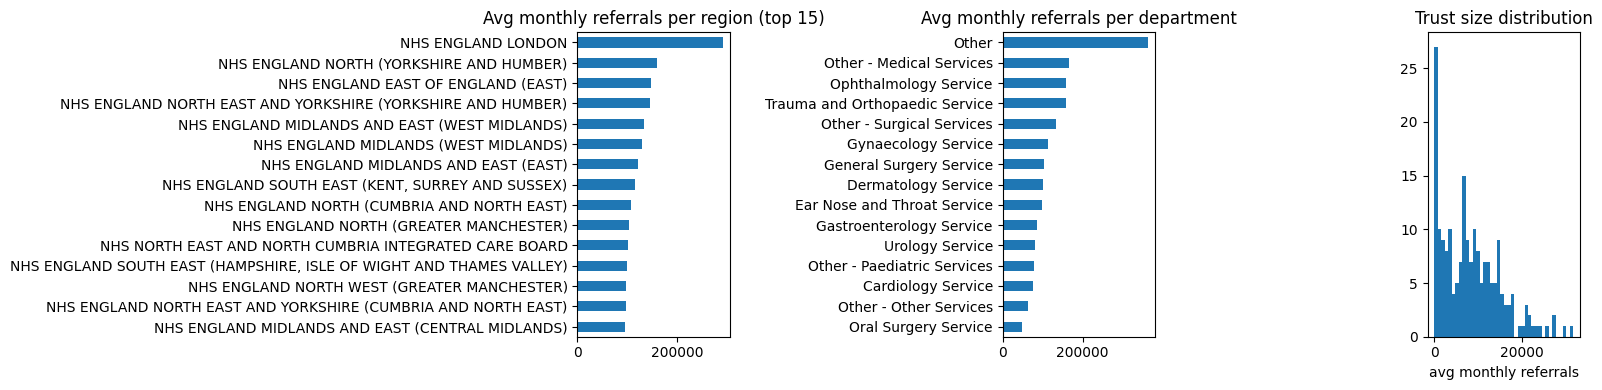

In [19]:
trust = (pub.groupby("Provider Org Code")
            .agg(months=("month", "nunique"), total_demand=("demand", "sum")).reset_index())
trust["avg_per_month"] = trust.total_demand / trust.months     # per-trust monthly mean
print(f"public providers with any demand      : {len(trust)}")
print(f"avg new referrals per trust per month : {trust.avg_per_month.mean():,.0f}")
print(trust.avg_per_month.describe().round(0).to_string())
print(f"\nlargest/smallest ratio: {trust.avg_per_month.max() / trust.avg_per_month.min():,.0f}x "
      f"— this heterogeneity is the case for per-client fine-tuning")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
region.set_index("Provider Parent Name").avg_per_month.head(15)[::-1].plot.barh(ax=ax[0])
ax[0].set_title("Avg monthly referrals per region (top 15)"); ax[0].set_ylabel("")
dept.set_index("name").avg_per_month.head(15)[::-1].plot.barh(ax=ax[1])
ax[1].set_title("Avg monthly referrals per department"); ax[1].set_ylabel("")
ax[2].hist(trust.avg_per_month, bins=40)                       # the size distribution
ax[2].set_title("Trust size distribution"); ax[2].set_xlabel("avg monthly referrals")
plt.tight_layout()

lowest  demand month : Apr 2020  493,749
highest demand month : Mar 2026  1,932,318
trough is 30% of the 96-month median
waiting list: 4,037,223 -> 7,045,510


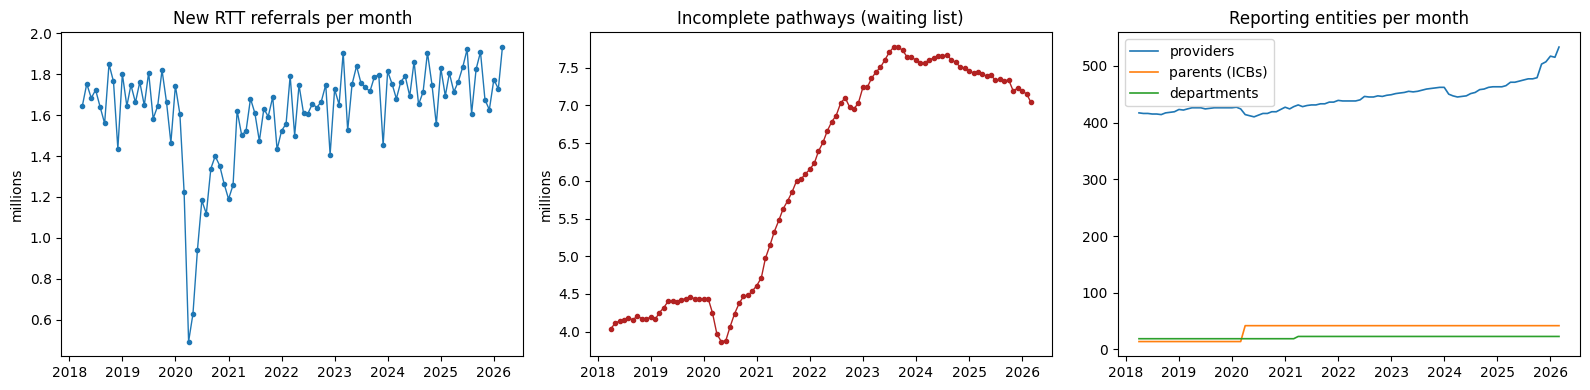

In [20]:
# national series and the COVID shock the forecaster has to survive
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(monthly.month, monthly.demand / 1e6, marker="o", ms=3, lw=1)
ax[0].set_title("New RTT referrals per month"); ax[0].set_ylabel("millions")
ax[1].plot(monthly.month, monthly.waiting / 1e6, marker="o", ms=3, lw=1, color="firebrick")
ax[1].set_title("Incomplete pathways (waiting list)"); ax[1].set_ylabel("millions")
ax[2].plot(monthly.month, monthly.providers, lw=1.2, label="providers")
ax[2].plot(monthly.month, monthly.parents, lw=1.2, label="parents (ICBs)")
ax[2].plot(monthly.month, monthly.tf_codes, lw=1.2, label="departments")
ax[2].set_title("Reporting entities per month"); ax[2].legend()
plt.tight_layout()

trough, peak = monthly.loc[monthly.demand.idxmin()], monthly.loc[monthly.demand.idxmax()]
print(f"lowest  demand month : {trough.month:%b %Y}  {trough.demand:,.0f}")
print(f"highest demand month : {peak.month:%b %Y}  {peak.demand:,.0f}")
print(f"trough is {trough.demand / monthly.demand.median() * 100:.0f}% of the 96-month median")
print(f"waiting list: {monthly.waiting.iloc[0]:,.0f} -> {monthly.waiting.iloc[-1]:,.0f}")

# H. GATE — verify the independent sector against ground truth

**Blocking.** The canonical table keeps every provider with a `sector` column, so sector filtering is a downstream one-line panel decision rather than something baked into the parquet. That is only safe if independent rows are *genuine demand* and not a reporting artefact. Four questions, answered with numbers:

- **(a)** do independents report real `Part_3` volumes with plausible dynamics, or only completed/incomplete pathways?
- **(b)** independent share over time, **per specialty** — flag any specialty where the share trends rather than holds
- **(c)** reporting behaviour: churn, months present, gaps, and how the five part types are populated
- **(d)** national totals with and without independents, so we know which published figure we reproduce

In [21]:
# (a) do independents populate Part_3, or only the completed/incomplete parts?
part_pop["sector"] = part_pop["Provider Org Code"].map(SECTOR)
pt_cols = [c for c in part_pop.columns if str(c).startswith("Part_")]      # the five part types
# share of provider-months in which each part type is non-zero, by sector
pop_rate = part_pop.groupby("sector")[pt_cols].apply(lambda g: (g > 0).mean() * 100).round(1)
print("(a) % of provider-months in which each part type is populated:")
print(pop_rate.to_string())
print()
ind_dem = prov_month[prov_month.sector == "independent"].groupby("month").demand.sum()
pub_dem = prov_month[prov_month.sector == "public"].groupby("month").demand.sum()
print(f"independent Part_3 demand: total {ind_dem.sum():,.0f}, mean {ind_dem.mean():,.0f}/month, "
      f"zero-months {int((ind_dem == 0).sum())}")
print(f"public       Part_3 demand: total {pub_dem.sum():,.0f}, mean {pub_dem.mean():,.0f}/month")
# if independents were an artefact their movements would not track the public sector
print(f"correlation of month-on-month % change, independent vs public: "
      f"{ind_dem.pct_change().corr(pub_dem.pct_change()):.3f}")

(a) % of provider-months in which each part type is populated:
RTT Part Type  Part_1A  Part_1B  Part_2  Part_2A  Part_3
sector                                                  
independent       86.1     97.0    99.8     87.2    98.3
public            85.7     99.7    99.9     84.5    99.7

independent Part_3 demand: total 11,541,248, mean 120,221/month, zero-months 0
public       Part_3 demand: total 143,908,428, mean 1,499,046/month
correlation of month-on-month % change, independent vs public: 0.943


independent share: first 6.20%, last 7.70%, min 3.94%, max 8.91%
[F-07] Independents DO report genuine Part_3 demand: 11,541,248 referrals over 96 months, 0 zero-months, share moving 6.20% -> 7.70%. Not an artefact of one part type.


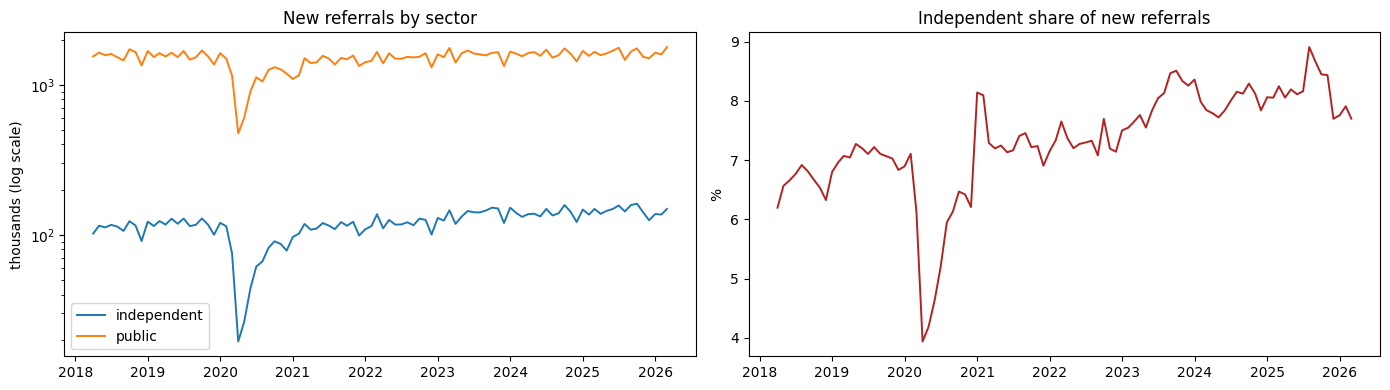

In [22]:
shr = ind_dem / (ind_dem + pub_dem) * 100                      # independent share of demand
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(ind_dem.index, ind_dem / 1e3, lw=1.4, label="independent")
ax[0].plot(pub_dem.index, pub_dem / 1e3, lw=1.4, label="public")
ax[0].set_yscale("log")                                        # log: the two differ by ~10x
ax[0].set_ylabel("thousands (log scale)"); ax[0].legend()
ax[0].set_title("New referrals by sector")
ax[1].plot(shr.index, shr, lw=1.4, color="firebrick")
ax[1].set_title("Independent share of new referrals"); ax[1].set_ylabel("%")
plt.tight_layout()
print(f"independent share: first {shr.iloc[0]:.2f}%, last {shr.iloc[-1]:.2f}%, "
      f"min {shr.min():.2f}%, max {shr.max():.2f}%")
finding("F-07", f"Independents DO report genuine Part_3 demand: {ind_dem.sum():,.0f} referrals over "
                f"96 months, {int((ind_dem == 0).sum())} zero-months, share moving "
                f"{shr.iloc[0]:.2f}% -> {shr.iloc[-1]:.2f}%. Not an artefact of one part type.")

In [23]:
# (b) independent share per specialty, over time
spec["sector"] = spec["Provider Org Code"].map(SECTOR)
piv = (spec.pivot_table(index=["Treatment Function Code", "month"], columns="sector",
                        values="Total All", aggfunc="sum").fillna(0))
piv["ind_share"] = piv["independent"] / (piv["independent"] + piv["public"]) * 100
piv.to_csv(REF / "specialty_sector_month.csv")                 # cached for later phases
summ = piv.groupby(level=0).ind_share.agg(["first", "last", "mean", "max"]).round(2)
summ["change_pp"] = (summ["last"] - summ["first"]).round(2)     # percentage-point move
print("independent share of new referrals by specialty (%):")
print(summ.sort_values("change_pp", ascending=False).to_string())

independent share of new referrals by specialty (%):
                         first   last   mean    max  change_pp
Treatment Function Code                                       
C_130                     6.20  19.65  14.47  23.80      13.45
C_150                     4.84   9.33   5.28  10.56       4.49
C_330                     6.81  11.11   9.64  13.90       4.30
C_100                     6.60  10.39   8.61  12.45       3.79
X02                       0.79   2.65   1.56   5.84       1.86
X01                       3.04   4.82   4.01   5.89       1.78
C_140                     2.87   4.38   3.11   4.71       1.51
X06                      17.02  18.25  18.91  30.91       1.23
C_160                     2.33   3.51   2.87   6.19       1.18
C_120                     5.94   6.71   5.70   7.43       0.77
C_320                     0.73   1.22   0.78   1.72       0.49
C_430                     0.63   1.02   0.81   1.19       0.39
C_400                     0.61   0.60   0.65   1.47      -0.01
C_

 code  pp_per_year  first  last  TRENDING
C_130        2.201   6.20 19.65      True
C_100        0.702   6.60 10.39      True
C_330        0.672   6.81 11.11      True
C_150        0.640   4.84  9.33      True
C_110        0.391  19.37 18.99     False
  X01        0.346   3.04  4.82     False
  X02        0.261   0.79  2.65     False
C_160        0.208   2.33  3.51     False
C_140        0.189   2.87  4.38     False
C_320        0.035   0.73  1.22     False
C_430        0.026   0.63  1.02     False
C_120        0.015   5.94  6.71     False
C_340        0.007   0.89  0.71     False
C_400        0.003   0.61  0.60     False
  X05       -0.004   1.27  0.89     False
C_300       -0.055   0.86  0.26     False
C_170       -0.060   1.52  0.00     False
  X04       -0.179   0.44  0.02     False
C_101       -0.187   5.77  5.00     False
C_410       -0.237   3.51  2.79     False
C_502       -0.244   5.74  3.47     False
C_301       -0.420  11.34  8.25     False
  X03       -0.667   3.24  0.00   

[F-08] Independent share TRENDS in 6 of 24 specialties (>0.5pp/yr). Fastest: C_130 at +2.20pp/yr (6.2% -> 19.6%). The sector mix is non-stationary, so a pooled model must carry the sector split explicitly rather than assume a fixed composition.


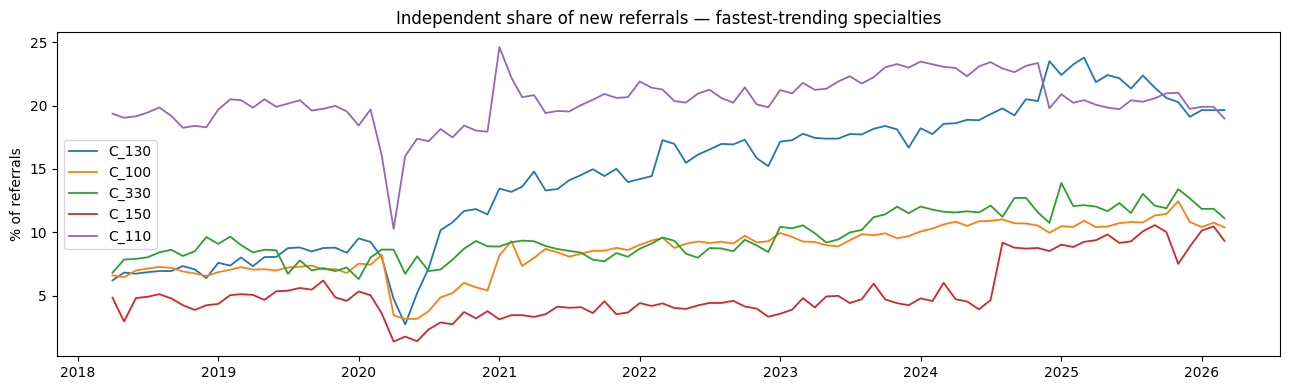

In [24]:
# flag specialties whose independent share TRENDS: slope in percentage points per year
slopes = []
for code, g in piv.groupby(level=0):                           # one specialty at a time
    s = g.reset_index()
    if s.ind_share.notna().sum() < 24 or s.ind_share.std() == 0:
        continue                                               # too little history to fit
    x = (s.month - s.month.min()).dt.days / 365.25              # years since first observation
    slope = np.polyfit(x, s.ind_share.fillna(0), 1)[0]          # linear fit, slope = pp/year
    slopes.append({"code": code, "pp_per_year": round(slope, 3),
                   "first": round(s.ind_share.iloc[0], 2), "last": round(s.ind_share.iloc[-1], 2)})
slopes = pd.DataFrame(slopes).sort_values("pp_per_year", ascending=False)
slopes["TRENDING"] = slopes.pp_per_year.abs() > 0.5             # >0.5pp/yr is drift, not noise
print(slopes.to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 4))
for code in slopes.head(5).code:                                # five fastest-trending specialties
    s = piv.loc[code].reset_index()
    ax.plot(s.month, s.ind_share, lw=1.3, label=code)
ax.set_title("Independent share of new referrals — fastest-trending specialties")
ax.set_ylabel("% of referrals"); ax.legend()
plt.tight_layout()
finding("F-08", f"Independent share TRENDS in {int(slopes.TRENDING.sum())} of {len(slopes)} "
                f"specialties (>0.5pp/yr). Fastest: {slopes.iloc[0].code} at "
                f"{slopes.iloc[0].pp_per_year:+.2f}pp/yr ({slopes.iloc[0]['first']:.1f}% -> "
                f"{slopes.iloc[0]['last']:.1f}%). The sector mix is non-stationary, so a pooled model "
                f"must carry the sector split explicitly rather than assume a fixed composition.")

In [25]:
# (c) reporting behaviour: churn, gaps, retirement
beh = census[census.months_present > 0].copy()                  # providers that ever reported demand
beh["window_len"] = (((beh.last_month - beh.first_month).dt.days / 30.44).round() + 1).astype(int)
beh["gaps"] = beh.window_len - beh.months_present               # months absent inside its own window
print("(c) reporting behaviour by sector:")
print(beh.groupby("sector").agg(
    providers=("code", "size"),
    median_months=("months_present", "median"),
    pct_full_96=("months_present", lambda s: (s == 96).mean() * 100),   # full-window share
    median_gaps=("gaps", "median"),
    pct_with_gaps=("gaps", lambda s: (s > 0).mean() * 100),
    pct_ods_retired=("ods_retired", lambda s: s.mean() * 100),
).round(1).to_string())
print()
print("entries by year (first month seen):")
print(beh.groupby([beh.first_month.dt.year, "sector"]).size().unstack(fill_value=0).to_string())
print()
print("exits by year (last month seen, excluding those still reporting):")
gone = beh[beh.last_month < latest_month]                       # stopped before the final month
print(gone.groupby([gone.last_month.dt.year, "sector"]).size().unstack(fill_value=0).to_string())

(c) reporting behaviour by sector:
             providers  median_months  pct_full_96  median_gaps  pct_with_gaps  pct_ods_retired
sector                                                                                         
independent        451           65.0         27.9          0.0           20.8              5.8
public             196           96.0         64.3          0.0           10.7              1.5

entries by year (first month seen):
sector       independent  public
first_month                     
2018                 239     189
2019                  20       4
2020                  18       1
2021                  25       1
2022                  18       0
2023                  21       1
2024                  29       0
2025                  48       0
2026                  33       0

exits by year (last month seen, excluding those still reporting):
sector      independent  public
last_month                     
2018                  4       4
2019              

[F-09] Reporting behaviour differs sharply by sector: 64% of public providers span all 96 months vs 28% of independents. The balanced-panel rule therefore performs most of the sector filtering by itself, as predicted.


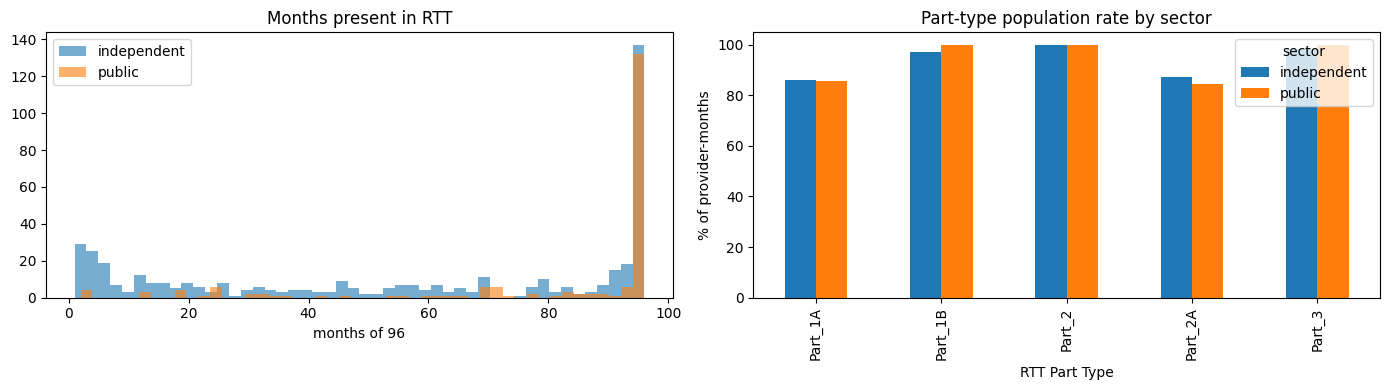

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for s, g in beh.groupby("sector"):                              # overlay the two distributions
    ax[0].hist(g.months_present, bins=48, alpha=0.6, label=s)
ax[0].set_title("Months present in RTT"); ax[0].set_xlabel("months of 96"); ax[0].legend()
pop_rate.T.plot.bar(ax=ax[1])                                   # part-type population by sector
ax[1].set_title("Part-type population rate by sector"); ax[1].set_ylabel("% of provider-months")
plt.tight_layout()
finding("F-09", f"Reporting behaviour differs sharply by sector: "
                f"{beh[beh.sector == 'public'].months_present.eq(96).mean() * 100:.0f}% of public "
                f"providers span all 96 months vs "
                f"{beh[beh.sector == 'independent'].months_present.eq(96).mean() * 100:.0f}% of "
                f"independents. The balanced-panel rule therefore performs most of the sector "
                f"filtering by itself, as predicted.")

In [27]:
# (d) which published national figure does our table reproduce?
d2all = df[df["RTT Part Type"] == "Part_2"]                     # latest month, all rows
d2real = d2all[d2all["Treatment Function Code"] != AGG].copy()  # specialties only
d2real["sector"] = d2real["Provider Org Code"].map(SECTOR)
variants = {                                                    # four defensible bases
    "all providers, specialties only (standard published basis)": d2real["Total All"].sum(),
    "public providers only, specialties only": d2real[d2real.sector == "public"]["Total All"].sum(),
    "independents only, specialties only": d2real[d2real.sector == "independent"]["Total All"].sum(),
    "all providers INCLUDING C_999 (wrong — double counts)": d2all["Total All"].sum(),
}
print(f"England incomplete pathways, {month_of(latest.name):%B %Y} — every variant:")
for k, v in variants.items():
    print(f"  {v:>14,.0f}   {k}")
base = variants["all providers, specialties only (standard published basis)"]
print(f"\nindependents are {variants['independents only, specialties only'] / base * 100:.2f}% "
      f"of the published-basis waiting list")
finding("F-10", f"Published-basis reconciliation, {month_of(latest.name):%b %Y}: our table yields "
                f"{base:,.0f} incomplete pathways on the all-providers / specialties-only basis, of "
                f"which {variants['independents only, specialties only']:,.0f} "
                f"({variants['independents only, specialties only'] / base * 100:.2f}%) are "
                f"independent. OPEN: confirm this against the NHS England press notice for the month.")

England incomplete pathways, March 2026 — every variant:
       7,045,510   all providers, specialties only (standard published basis)
       6,603,854   public providers only, specialties only
         441,656   independents only, specialties only
      14,091,020   all providers INCLUDING C_999 (wrong — double counts)

independents are 6.27% of the published-basis waiting list
[F-10] Published-basis reconciliation, Mar 2026: our table yields 7,045,510 incomplete pathways on the all-providers / specialties-only basis, of which 441,656 (6.27%) are independent. OPEN: confirm this against the NHS England press notice for the month.


# I. KH03 overnight beds

In [28]:
print(f"workbooks: {len(kh)}   total {sum(f.stat().st_size for f in kh) / 1e6:.1f} MB")
print("extensions:", dict(collections.Counter(f.suffix.lower() for f in kh)))   # xls vs xlsx mix
print("earliest by name:", kh[0].name)
print("latest by name  :", kh[-1].name)

workbooks: 61   total 11.0 MB
extensions: {'.xlsx': 50, '.xls': 11}
earliest by name: 1920-Q1-Beds-Open-Overnight-Web_File-Final-DE5WC.xlsx
latest by name  : Beds-Open-Overnight-Web_File-Q4-2025-26.xlsx


# J. Findings summary, then delete the archives

In [29]:
print(f"{len(findings)} findings recorded in this run:\n")
for fid, text in findings:                                      # everything established above
    print(f"[{fid}] {text}\n")
pd.DataFrame(findings, columns=["id", "finding"]).to_csv(REF / "findings.csv", index=False)

12 findings recorded in this run:

[F-01] Integrity PASS=True. 96/96 months present and structurally sound; archives CRC-clean (0 tested); extraction sizes exact; no Period/filename mismatches; no truncated rows; all 61 KH03 workbooks valid; no duplicate provider codes in the reference.

[F-02] Schema break at Apr 2021: 69 columns for 36 months, then 121 for 60. The single ['Gt 52 Weeks SUM 1'] column is replaced by 53 weekly bands running to 104w. The 52 bands below 52w are identical across both eras, so any >18w metric is era-stable and only the >52 tail differs. Handling rule belongs to data_processing.ipynb, not here.

[F-03] Part_3 (new referrals) has NO populated week bands, by design: a new referral has waited ~0 weeks, so bands are meaningless for it. Demand = 'Total All' alone. Bands only ever feed the backlog / agentic side. Expected, not a defect — do not 'fix'.

[F-04] C_999 is an EXACT aggregate, verified across all 96 months x 5 part types x every provider (199,410 groups

In [30]:
# the csvs are the only copy needed now, and section A verified them against these archives
freed = sum(z.stat().st_size for z in zips)                     # bytes about to be reclaimed
for z in zips:
    z.unlink()                                                  # delete each archive
if RTT_ZIPS.exists() and not any(RTT_ZIPS.iterdir()):
    RTT_ZIPS.rmdir()                                            # remove the now-empty folder
print(f"deleted {len(zips)} archives, freed {freed / 1e6:.0f} MB")
print("csvs still on disk:", len(list(RTT_CSV.glob('*.csv'))))

deleted 0 archives, freed 0 MB
csvs still on disk: 96
